In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [4]:
df = pd.read_csv('diabetes_prediction_dataset.csv')

In [5]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [6]:
print("Dataset Shape:", df.shape)
print("\nData Types and Missing Values:")
df.info()

Dataset Shape: (100000, 9)

Data Types and Missing Values:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 8.0 MB


In [7]:
df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [8]:
print("Gender unique values:", df['gender'].unique())
print("Smoking history unique values:", df['smoking_history'].unique())

Gender unique values: <ArrowStringArray>
['Female', 'Male', 'Other']
Length: 3, dtype: str
Smoking history unique values: <ArrowStringArray>
['never', 'No Info', 'current', 'former', 'ever', 'not current']
Length: 6, dtype: str


In [9]:
le_gender = LabelEncoder()
le_smoking = LabelEncoder()

In [10]:
df['gender'] = le_gender.fit_transform(df['gender'])
df['smoking_history'] = le_smoking.fit_transform(df['smoking_history'])

In [11]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,0,80.0,0,1,4,25.19,6.6,140,0
1,0,54.0,0,0,0,27.32,6.6,80,0
2,1,28.0,0,0,4,27.32,5.7,158,0
3,0,36.0,0,0,1,23.45,5.0,155,0
4,1,76.0,1,1,1,20.14,4.8,155,0


In [12]:
X = df.drop(columns=['diabetes'])
y = df['diabetes']

In [13]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (100000, 8)
Target shape: (100000,)


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set size:", X_train.shape[0])
print("Testing set size:", X_test.shape[0])

Training set size: 80000
Testing set size: 20000


In [15]:
clf = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)

In [16]:
clf.fit(X_train, y_train)
print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [17]:
y_pred = clf.predict(X_test)

In [18]:
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {acc * 100:.2f}%\n")

Accuracy Score: 97.23%



In [19]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99     18300
           1       1.00      0.67      0.81      1700

    accuracy                           0.97     20000
   macro avg       0.99      0.84      0.90     20000
weighted avg       0.97      0.97      0.97     20000



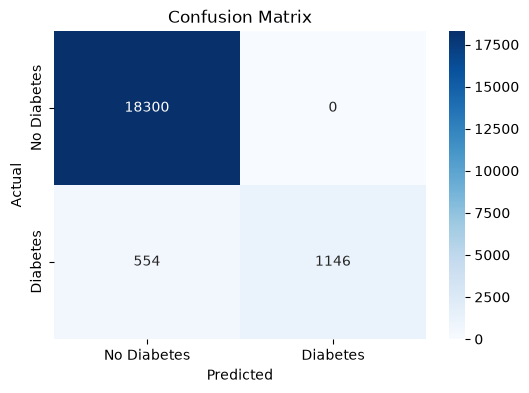

In [20]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No Diabetes', 'Diabetes'], 
            yticklabels=['No Diabetes', 'Diabetes'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

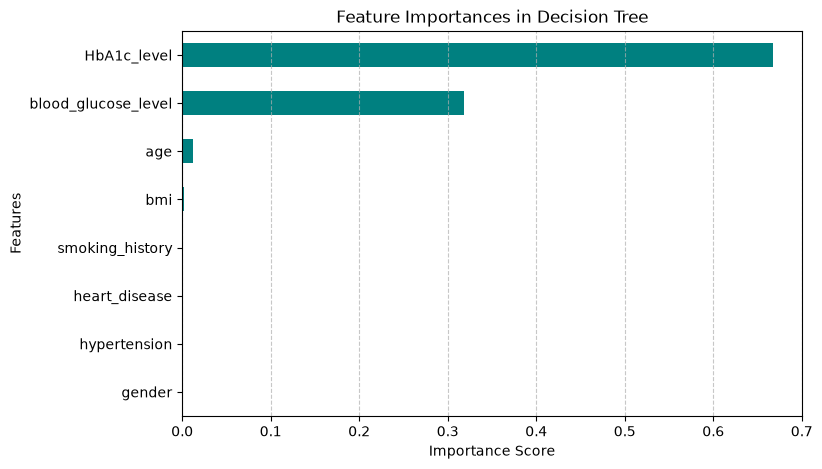

In [21]:
# Feature importance plot
feature_importances = pd.Series(clf.feature_importances_, index=X.columns)
feature_importances.sort_values().plot(kind='barh', color='teal', figsize=(8, 5))

plt.title('Feature Importances in Decision Tree')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

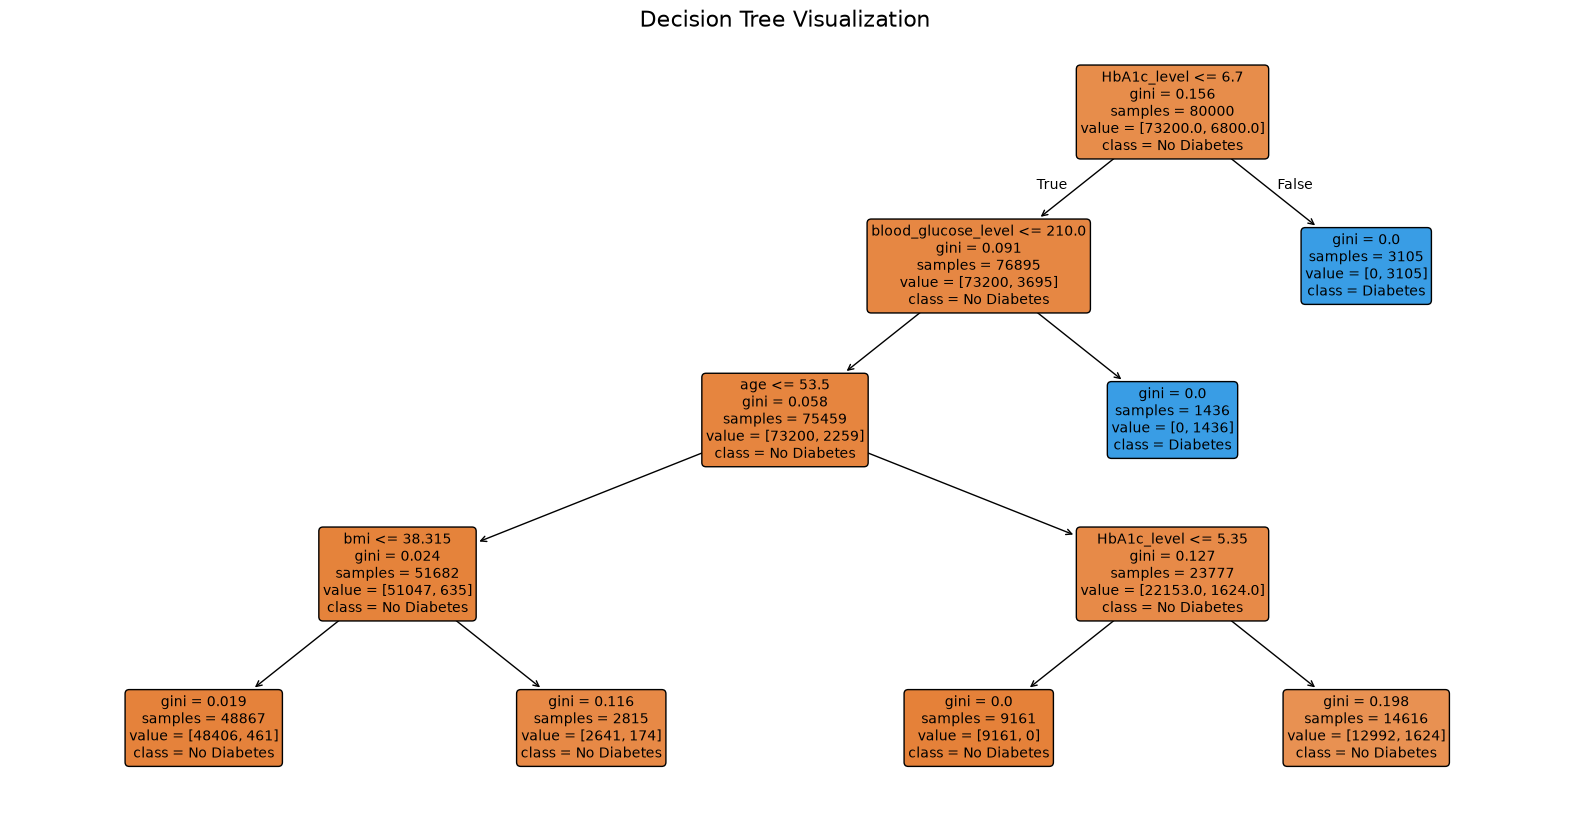

In [22]:
plt.figure(figsize=(20, 10))
plot_tree(
    clf, 
    feature_names=X.columns, 
    class_names=['No Diabetes', 'Diabetes'], 
    filled=True, 
    rounded=True, 
    fontsize=10
)
plt.title('Decision Tree Visualization', fontsize=16)
plt.show()

In [23]:
# Sample unseen patient data:
# [gender (1=Male, 0=Female), age, hypertension, heart_disease, smoking_history, bmi, HbA1c_level, blood_glucose_level]
sample_patient = pd.DataFrame([{
    'gender': le_gender.transform(['Female'])[0],
    'age': 55.0,
    'hypertension': 0,
    'heart_disease': 0,
    'smoking_history': le_smoking.transform(['never'])[0],
    'bmi': 28.5,
    'HbA1c_level': 7.0,
    'blood_glucose_level': 160
}])

prediction = clf.predict(sample_patient)[0]
result = "Diabetes" if prediction == 1 else "No Diabetes"
print("Prediction for Sample Patient:", result)

Prediction for Sample Patient: Diabetes
